In [36]:
from pathlib import Path

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

In [38]:
PROJECT_ROOT = Path("/Users/yaasarpong/Desktop/PHD/Year 4 fall/finance-volatility")

In [39]:
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"

In [40]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [41]:
sns.set_theme(style="whitegrid")

In [42]:
def save_figure(fig, filename): 
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [8]:
#load the data

In [43]:
data = pd.read_csv(DATA_DIR / "financial_model_data.csv",
                   parse_dates=["date","target_date"])

In [44]:
train = data.loc[data["sample"].eq("Training")].copy()

In [45]:
analysis_columns = ["sp500", "vix", "treasury_10yr", "log_return",
                    "absolute_return", "squared_return", "vix_change",
                    "treasury_change", "target_next_day"]

In [46]:
print("Training observations:", len(train))

Training observations: 1546


In [47]:
print("Last training target date:", train["target_date"].max())

Last training target date: 2022-12-30 00:00:00


In [15]:
# plot the series over time

In [48]:
series_to_plot = {"sp500": "S&P 500 (index points)",
                  "vix": "VIX (annualized %)",
                  "treasury_10yr": "10-year Treasury yield (%)",
                  "log_return": "S&P 500 log return (%)",
                  "absolute_return": "Absolute log return (%)",}

Text(0.5, 0, 'Observation datee')

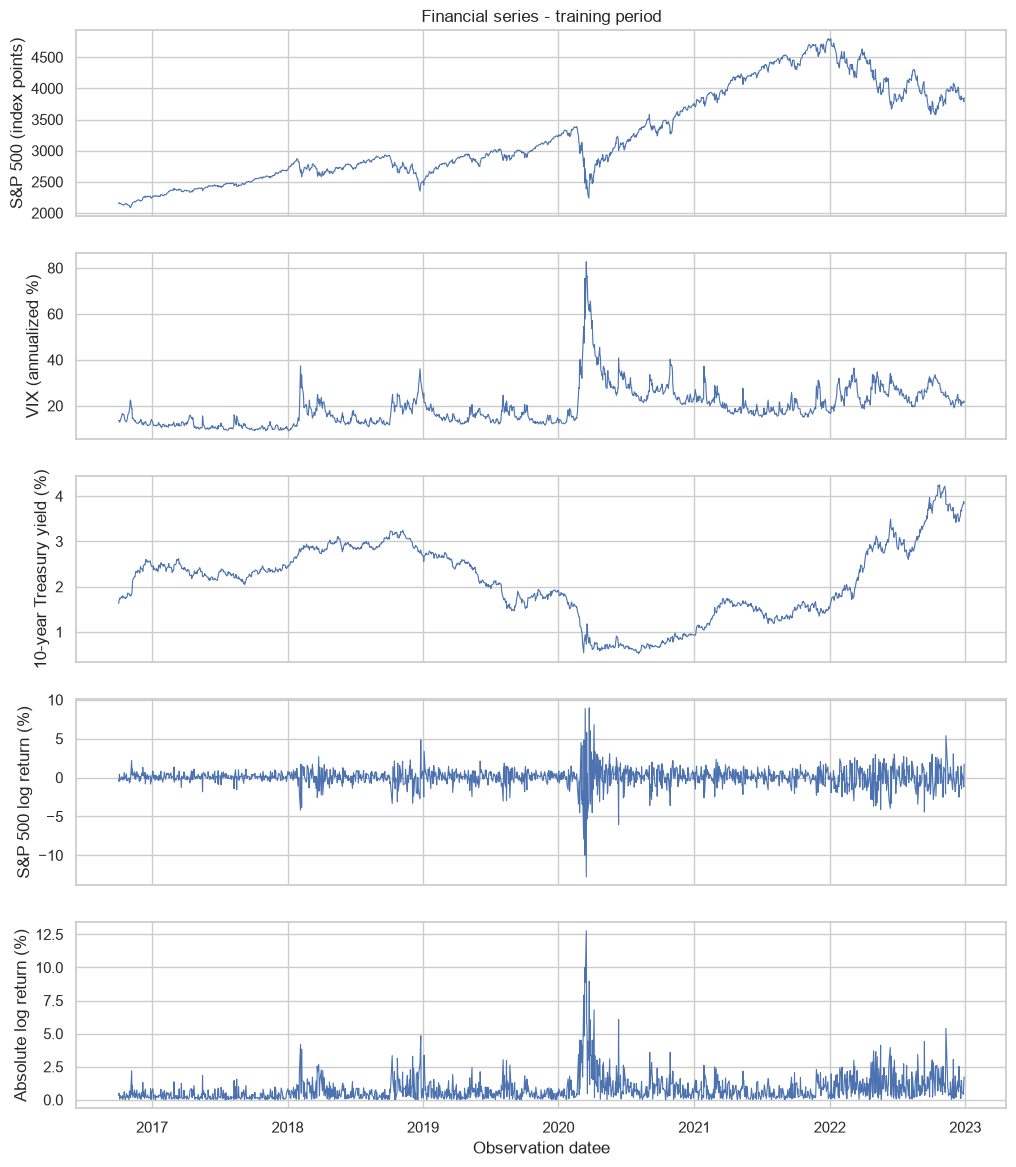

In [49]:
fig, axes = plt.subplots(len(series_to_plot),1,figsize=(12,14),
                         sharex=True)

for ax, (column, label) in zip(axes, series_to_plot.items()):
    ax.plot(train["date"], train[column], linewidth=0.8)
    ax.set_ylabel(label)

axes[0].set_title("Financial series - training period")
axes[-1].set_xlabel("Observation datee")

In [50]:
save_figure(fig, "day10_time_series.png")

In [21]:
# summarize distributions

In [51]:
summary = train[analysis_columns].describe().T

In [52]:
summary["skewness"] = train[analysis_columns].skew()
summary["excess_kurtosis"] = train[analysis_columns].kurt()

In [53]:
summary.to_csv(RESULTS_DIR / "day10_summary_statistics.csv")

In [54]:
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,skewness,excess_kurtosis
sp500,1546.0,3238.879,734.424,2085.180,2670.178,2975.975,3901.278,4796.560,0.482,-1.068
vix,1546.0,19.405,8.569,9.140,12.942,17.530,23.348,82.690,2.197,9.152
treasury_10yr,1546.0,2.108,0.820,0.520,1.540,2.220,2.770,4.250,-0.057,-0.583
log_return,1546.0,0.039,1.260,-12.765,-0.375,0.074,0.597,8.968,-0.873,15.877
absolute_return,1546.0,0.787,0.985,0.000,0.189,0.490,1.033,12.765,4.116,29.892
squared_return,1546.0,1.589,6.683,0.000,0.036,0.240,1.067,162.951,14.513,280.457
vix_change,1546.0,0.001,2.113,-17.640,-0.818,-0.120,0.567,24.860,2.689,31.806
treasury_change,1546.0,0.001,0.050,-0.300,-0.030,0.000,0.030,0.290,-0.034,3.596
target_next_day,1546.0,0.786,0.983,0.000,0.189,0.490,1.033,12.765,4.127,30.078


Text(0.5, 0, 'Absolute log return (%)')

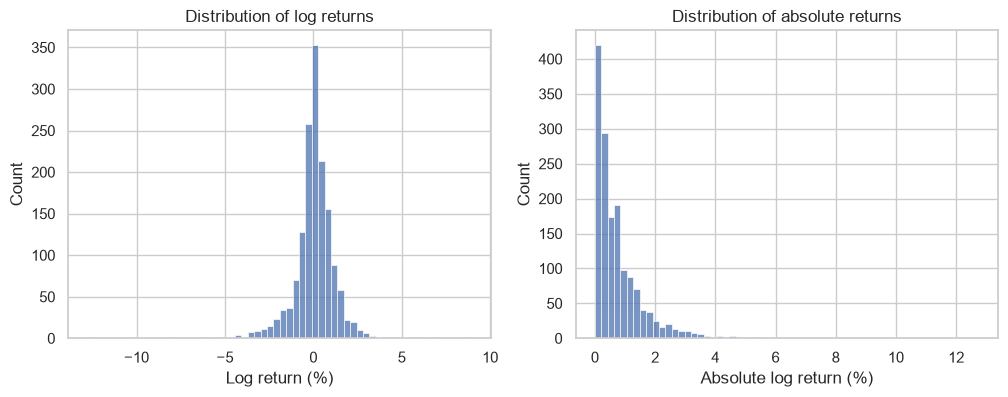

In [55]:
fig, axes = plt.subplots(1,2,figsize=(12,4))

sns.histplot(data=train, x="log_return",bins=60, ax=axes[0])
axes[0].set_title("Distribution of log returns")
axes[0].set_xlabel("Log return (%)")

sns.histplot(data=train,x="absolute_return",bins=60,ax=axes[1])
axes[1].set_title("Distribution of absolute returns")
axes[1].set_xlabel("Absolute log return (%)")

In [56]:
save_figure(fig,"day10_return_distributions.png")

In [ ]:
# examine autocorrelation

In [57]:
acf_columns = { "log_return": "ACF: log returns",
                "squared_return": "ACF: squared returns",
                "absolute_return": "ACF: absolute returns"}

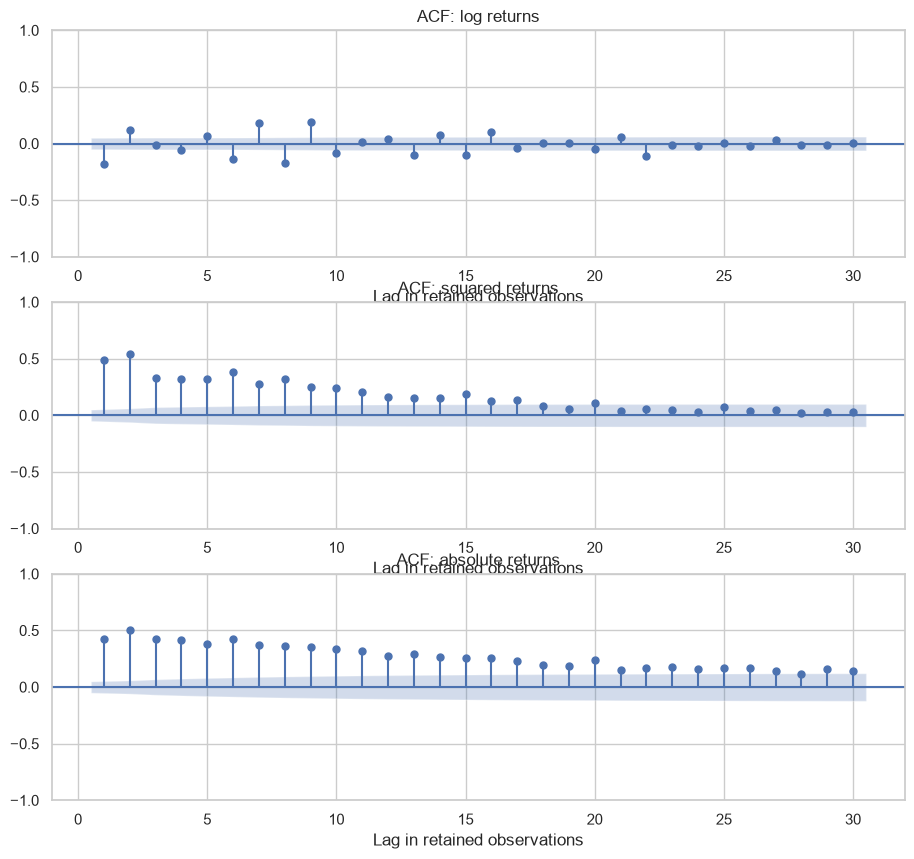

In [58]:
fig, axes = plt.subplots(3,1,figsize=(11,10))

for ax, (column, title) in zip(axes, acf_columns.items()):
    plot_acf(train[column],lags=30,zero=False,alpha=0.05,ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Lag in retained observations")

In [59]:
save_figure(fig,"day10_autocorrelation.png")

In [ ]:
# inspect extreme returns and predictor relationships

In [61]:
extreme_returns = train.nlargest(10,"absolute_return")[
    ["date","sp500","log_return","absolute_return", "vix"]]

In [62]:
display(extreme_returns)

,date,sp500,log_return,absolute_return,vix
853,2020-03-16,2386.13,-12.765214,12.765214,82.69
851,2020-03-12,2480.64,-9.994485,9.994485,75.47
859,2020-03-24,2447.33,8.968316,8.968316,61.67
852,2020-03-13,2711.02,8.880836,8.880836,57.83
848,2020-03-09,2746.56,-7.901039,7.901039,54.46
868,2020-04-06,2663.68,6.796823,6.796823,45.24
914,2020-06-11,3002.10,-6.075276,6.075276,40.79
861,2020-03-26,2630.07,6.054383,6.054383,61.00
854,2020-03-17,2529.19,5.822629,5.822629,75.91
1514,2022-11-10,3956.37,5.395250,5.395250,23.53


In [63]:
extreme_returns.to_csv(RESULTS_DIR / "day10_extreme_returns.csv", index=False)

In [65]:
predictors = ["vix","treasury_change","absolute_return"]

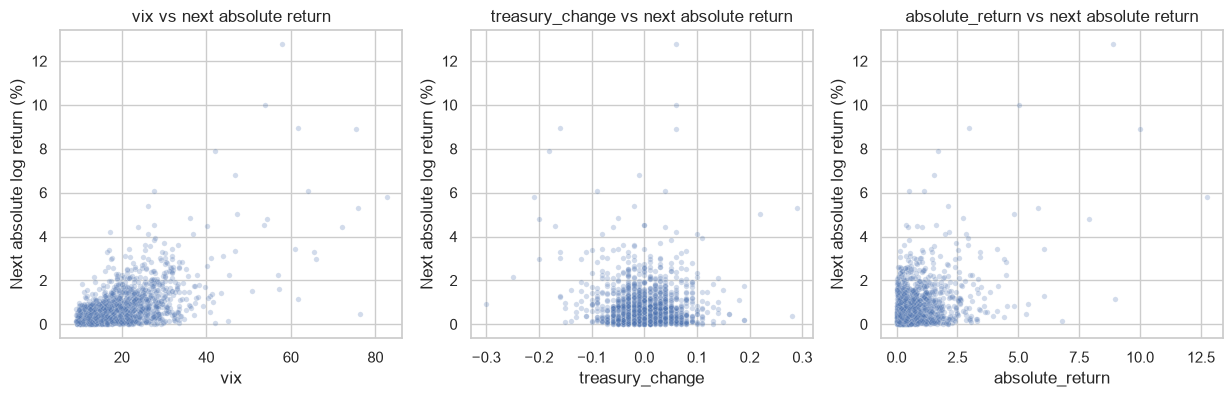

In [66]:
fig, axes = plt.subplots(1,3,figsize=(15,4))

for ax, predictor in zip(axes, predictors):
    sns.scatterplot(data=train, x=predictor, y="target_next_day",
                    alpha=0.25,s=15,ax=ax)
    ax.set_title(f"{predictor} vs next absolute return")
    ax.set_ylabel("Next absolute log return (%)")

In [67]:
save_figure(fig,"day10_predictor_relationships.png")

In [68]:
relationships = pd.DataFrame({"Pearson": [
    train[p].corr(train["target_next_day"],method="pearson") 
    for p in predictors ], "Spearman": [ train[p].corr(train["target_next_day"],
                                                       method="spearman")
                                         for p in predictors]},
                             index=predictors)
                                                       
                                  
    

In [69]:
relationships.index.name = "predictor"

In [70]:
display(relationships.round(3))

,Pearson,Spearman
predictor,,
vix,0.600,0.516
treasury_change,-0.074,-0.051
absolute_return,0.427,0.250


In [72]:
relationships.to_csv(RESULTS_DIR / "day10_predictor_correlations.csv")

**Your ACF plots are now displaying correctly. The main finding is clear: large market movements cluster together, and VIX has the strongest association with your next-observation volatility target among the three predictors examined.**

Here is how to interpret your results.

**1. The time-series plots show volatility clustering.**

The return series has calm periods with small movements and turbulent periods with repeated large positive and negative movements. This is particularly visible in early 2020, with further elevated activity during 2022.

The absolute-return plot makes this easier to see because it measures movement size regardless of direction. This supports investigating whether recent volatility helps forecast subsequent volatility.

**2. The ACF confirms persistent dependence in return magnitudes.**

| Series | What your plot shows | Interpretation |
|---|---|---|
| Log returns | Positive and negative spikes, with several outside the confidence bands | Some linear dependence is present; you should not describe returns as completely uncorrelated. |
| Squared returns | Strong positive autocorrelation at early lags, declining toward zero | Large squared movements tend to occur close together. |
| Absolute returns | Positive autocorrelation that persists across much of the 30-lag range | Return magnitude shows sustained persistence. |

Absolute returns appear **more persistent at longer lags** than squared returns, although squared returns have slightly higher autocorrelation at the first two lags.

The bands are approximate, pointwise intervals. Individual spikes should not be treated as definitive evidence of predictability, particularly with extreme observations and many lags examined.

**3. Most returns are small, but extreme movements matter.**

Your summary statistics show:

| Statistic | Value | Meaning |
|---|---:|---|
| Mean log return | 0.039% | Average signed return is close to zero. |
| Standard deviation of log returns | 1.260 percentage points | Returns vary substantially around their mean. |
| Median absolute return | 0.490% | Half of the observed absolute log returns are at or below this value. |
| Mean absolute return | 0.787% | Large movements pull the mean above the median. |
| Log-return skewness | −0.873 | The return distribution is asymmetric toward negative values. |
| Log-return excess kurtosis | 15.877 | Extreme observations contribute much more strongly than under a normal distribution. |

Absolute returns are strongly right-skewed, with skewness **4.116**. Squaring returns amplifies extreme observations further: squared-return skewness is **14.513**.

This makes it useful to report both **MAE and RMSE** later: RMSE gives greater weight to large forecast errors.

**4. Your extreme observations are concentrated in 2020.**

Nine of the ten largest absolute returns listed occur in March–June 2020. The largest is **March 16, 2020**, with a log return of **−12.765%** and VIX of **82.69**.

Remember that **−12.765% is a log return**, not the ordinary percentage price change.

Keep these observations unless comparison with the source reveals an error. Their concentration also means that a relatively short turbulent period may strongly influence your correlations and ACF.

**5. VIX has the strongest observed relationship with the target.**

| Predictor | Pearson | Spearman | Interpretation |
|---|---:|---:|---|
| VIX | 0.600 | 0.516 | Higher VIX is associated with larger subsequent absolute returns. |
| Current absolute return | 0.427 | 0.250 | Larger current movements tend to precede larger subsequent movements. |
| Treasury-yield change | −0.074 | −0.051 | Little evidence of a strong standalone linear or monotonic relationship. |

These results support testing VIX and recent absolute returns as predictors. They **do not yet establish improved forecasting performance**. Treasury changes could still provide information in combination with other variables.

**Before marking Day 10 complete:** your tables now show **1,546 valid observations per variable**, compared with the earlier 1,573 training rows. That is consistent with additional filtering, but the screenshots alone cannot confirm the reason. Verify that:

- Returns and targets were calculated **before** filtering missing predictors.
- Splits use `target_date`, with all training outcomes dated through December 2022.
- All figures were regenerated from the same corrected dataset.

Your ACF currently measures lags in **retained observations**. For a strict trading-day ACF, use the full S&P 500 return sequence before removing dates with missing VIX or Treasury predictors.